# Session 10 — How Text Becomes Numbers

Sessions 8 and 9 turned pictures into grids of numbers. Text needs a different step first: a sentence has to be cut into pieces and each piece given a number. This session builds that pipeline on 37,500 movie reviews labelled positive or negative, and compares two ways of reading them: counting words (TF-IDF with a logistic regression) and a small LSTM network that reads them in order.

The question to keep in mind is whether order matters. "Not good" and "good" share a word and mean opposite things.

**By the end of the session you should be able to:**

1. describe how text becomes tokens, then token ids, then vectors;
2. explain what word pairs (bigrams) add to a word-count model, and read their effect in the weights;
3. compare a word-count model with an LSTM on the same split and say honestly which wins here.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `torch` and `huggingface_hub` (with `pyarrow` to read the files). The first run downloads the IMDB reviews from the Hugging Face hub (two files of 20 MB). The saved outputs came from a laptop GPU, where the notebook took two to three minutes. On a CPU, the LSTM is the slow part and may take several minutes. Your numbers may differ slightly from the ones quoted in the text.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # lets the GPU repeat a run exactly

import re
import copy
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from huggingface_hub import hf_hub_download
from huggingface_hub.utils import disable_progress_bars, logging as hub_logging
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

SEED, VOCAB, MAXLEN = 0, 20_000, 200
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.use_deterministic_algorithms(True)
disable_progress_bars()
hub_logging.set_verbosity_error()  # hide the hub's notice about anonymous downloads


def load_imdb(split):
    """The 50,000 IMDB reviews (Maas et al., 2011), as published on the Hugging Face hub: 25,000 for training, 25,000 for testing."""
    return pd.read_parquet(hf_hub_download("stanfordnlp/imdb", f"plain_text/{split}-00000-of-00001.parquet", repo_type="dataset"))


def clean(text):
    return text.replace("<br />", " ")  # the reviews contain HTML line breaks


all_train, test = load_imdb("train"), load_imdb("test")
order = np.random.default_rng(SEED).permutation(len(all_train))
train, val = all_train.iloc[order[:10_000]], all_train.iloc[order[10_000:12_500]]
text_train, text_val, text_test = [[clean(t) for t in part["text"]] for part in (train, val, test)]
y_train, y_val, y_test = [part["label"].to_numpy() for part in (train, val, test)]

print(f"{len(text_train):,} training reviews, {len(text_val):,} validation, {len(text_test):,} test.  Share positive: {y_train.mean():.3f}")
print("\nReview 0 (label", y_train[0], "):", text_train[0][:400], "...")

10,000 training reviews, 2,500 validation, 25,000 test.  Share positive: 0.497

Review 0 (label 1 ): We always watch American movies with their particular accents from each region (south, west, etc). We have the same here. All foreign people must to watch this movie and need to have a open mind to accept another culture, besides American and European almost dominate the cinematographic industry.  This movie tell us about a parallel world which it isn't figured even for those who live in a big cit ...


## 1. The data

The IMDB dataset (Andrew Maas and colleagues, 2011) has 50,000 movie reviews labelled positive or negative, split in half for training and testing. We download it as raw text. The reviews contain HTML line breaks (`<br />`), which `clean` removes. We use 10,000 of the training reviews for training, 2,500 for validation (to decide when to stop the LSTM) and the standard 25,000 for testing. Of the training reviews, 0.497 are positive, so the baseline accuracy is 0.5.

Review 0 is positive, and it shows what real text looks like: "All foreign people must to watch this movie" is from a writer whose English is not perfect. A model has to cope with typing errors, slang and grammar like this.

In [2]:
sentence = "The movie was not good at all."
words = sentence.lower().replace(".", "").split()
vocabulary = {w: i for i, w in enumerate(sorted(set(words)))}
print("words:     ", words)
print("characters:", list(sentence[:14]), "...")
print("token ids: ", [vocabulary[w] for w in words], " from vocabulary", vocabulary)


def tokenize(text):
    return re.findall(r"[a-z0-9']+", text.lower())  # lower case, then keep runs of letters, digits and apostrophes


lengths = [len(tokenize(t)) for t in text_train]
print("\nThe first review as tokens:", tokenize(text_train[0])[:12], "...")
print("Length of the training reviews, in words: median", int(np.median(lengths)), " 90th percentile", int(np.percentile(lengths, 90)))

words:      ['the', 'movie', 'was', 'not', 'good', 'at', 'all']
characters: ['T', 'h', 'e', ' ', 'm', 'o', 'v', 'i', 'e', ' ', 'w', 'a', 's', ' '] ...
token ids:  [5, 3, 6, 4, 2, 1, 0]  from vocabulary {'all': 0, 'at': 1, 'good': 2, 'movie': 3, 'not': 4, 'the': 5, 'was': 6}



The first review as tokens: ['we', 'always', 'watch', 'american', 'movies', 'with', 'their', 'particular', 'accents', 'from', 'each', 'region'] ...
Length of the training reviews, in words: median 172  90th percentile 444


## 2. Tokens and ids

A model can't read letters. The first step is to cut the text into **tokens**. The simplest choice is words, as in the first line. Characters give a tiny vocabulary but long sequences. Modern language models use pieces in between, called subwords; Session 11 shows how BERT splits words into them.

The second step is to give every token in the vocabulary a whole number, its **id**. The ids are labels: id 5 is not "bigger" than id 3. In the example the seven words get ids 5, 3, 6, 4, 2, 1, 0. Here the vocabulary is sorted alphabetically; the real one, built in section 4, numbers the words of the training reviews by how common they are.

`tokenize` is the word splitter used for the LSTM: lower case, then runs of letters, digits and apostrophes. Reviews have a median of 172 words, but the longest are much longer: the 90th percentile is 444. For the LSTM we will cut or pad every review to 200 tokens.

In [3]:
unigram = make_pipeline(TfidfVectorizer(max_features=50_000, sublinear_tf=True), LogisticRegression(max_iter=2000))
bigram = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=200_000, sublinear_tf=True), LogisticRegression(max_iter=2000))
for model in (unigram, bigram):
    model.fit(text_train, y_train)

print(f"Single words only:        validation {unigram.score(text_val, y_val):.3f}   test {unigram.score(text_test, y_test):.3f}")
print(f"Words and word pairs:     validation {bigram.score(text_val, y_val):.3f}   test {bigram.score(text_test, y_test):.3f}")

Single words only:        validation 0.884   test 0.877


Words and word pairs:     validation 0.889   test 0.884


## 3. Counting words: TF-IDF

The **bag-of-words** idea ignores order and records which words appear and how often. **TF-IDF** weights each word count by how rare the word is across reviews, so common words like "the" count for little. A logistic regression on those weights learns one number per word: positive numbers push towards a positive review.

With single words, the model scores 0.877 on the test set. Adding word pairs (**bigrams**, such as "not good") as extra features raises that to 0.884. That is 0.7 points on 25,000 reviews, a small but real gain, since the test set is large. We now look at where it comes from.

> **Pause:** the single-word model can only add up a weight for "not" and a weight for "good". The word-pair model also has a feature for "not good". What weight do you expect it to learn for that pair: positive, negative, or close to zero?

In [4]:
vectorizer, classifier = bigram.named_steps["tfidfvectorizer"], bigram.named_steps["logisticregression"]
weights = pd.Series(classifier.coef_[0], index=vectorizer.get_feature_names_out())
uni_weights = pd.Series(unigram.named_steps["logisticregression"].coef_[0], index=unigram.named_steps["tfidfvectorizer"].get_feature_names_out())

print("Weights in the single-word model:", {w: round(float(uni_weights[w]), 2) for w in ["good", "bad", "not", "great", "waste"]})
print("Weights in the word-pair model:  ", {w: round(float(weights[w]), 2) for w in ["good", "not good", "not bad", "not great", "bad", "waste of"] if w in weights.index})
print("\nMost negative bigrams:", [w for w in weights[weights.index.str.contains(" ")].nsmallest(8).index])
print("Most positive bigrams:", [w for w in weights[weights.index.str.contains(" ")].nlargest(8).index])

Weights in the single-word model: {'good': 1.49, 'bad': -6.34, 'not': -1.6, 'great': 6.27, 'waste': -4.59}
Weights in the word-pair model:   {'good': 0.86, 'not good': -0.94, 'not bad': 0.36, 'not great': 0.24, 'bad': -5.95, 'waste of': -2.21}

Most negative bigrams: ['the worst', 'to be', 'waste of', 'at all', 'the only', 'the original', 'supposed to', 'not even']
Most positive bigrams: ['the best', 'is great', 'it is', 'one of', 'must see', 'see it', 'my favorite', 'this is']


A single-word model gives "good" a positive weight (1.49) and "not" a negative one (−1.6), and has to add them up. It can't tell "not good" from "good". The word-pair model has a feature for the pair, and it learns −0.94 for "not good" while the weight on "good" itself falls to 0.86. Other pairs it found were negative: "the worst", "waste of", "supposed to", "not even"; positive ones include "the best", "is great", "must see" and "my favorite".

Pairs are not a full solution. "not bad" gets a weight of only 0.36, because "bad" alone has such a strong weight (−5.95) and "not bad" is rare in 10,000 reviews. Bigrams capture a few short phrases and nothing longer.

> **Pause:** the next model reads each review in order, word by word, so it could in principle learn what "not" does to the words after it. On these 10,000 reviews, will it beat the word-pair model's 0.884?

embedding Embedding(20000, 32, padding_idx=0)           parameters 640,000
lstm      LSTM(32, 32, batch_first=True)                parameters   8,448
out       Linear(in_features=32, out_features=1, bias=True) parameters      33
total                                                   parameters 648,481


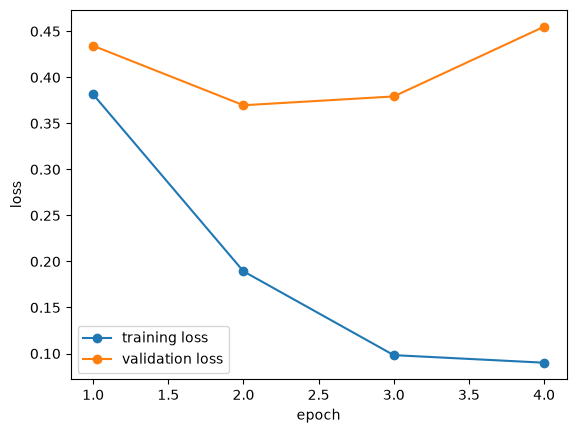

training loss by epoch:   [0.38, 0.19, 0.1, 0.09]
validation loss by epoch: [0.43, 0.37, 0.38, 0.45]


LSTM: 4 epochs, kept epoch 2; accuracy: validation 0.843   test 0.825


In [5]:
# The vocabulary: the 19,998 most common words in the training reviews. Id 0 is padding, id 1 stands for any other word.
counts = Counter(token for text in text_train for token in tokenize(text))
word_to_id = {word: i + 2 for i, (word, _) in enumerate(counts.most_common(VOCAB - 2))}
id_to_word = {i: w for w, i in word_to_id.items()}


def encode(texts):
    """Token ids, cut or padded with 0 at the end to MAXLEN, plus each review's length before padding."""
    ids = [[word_to_id.get(token, 1) for token in tokenize(t)][:MAXLEN] for t in texts]
    padded = torch.zeros(len(ids), MAXLEN, dtype=torch.long)
    for row, seq in enumerate(ids):
        padded[row, :len(seq)] = torch.tensor(seq)
    return padded, torch.tensor([max(len(seq), 1) for seq in ids])


class LSTMClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        torch.manual_seed(SEED)
        self.embedding = nn.Embedding(VOCAB, 32, padding_idx=0)
        self.lstm = nn.LSTM(32, 32, batch_first=True)
        self.out = nn.Linear(32, 1)
        with torch.no_grad():
            nn.init.uniform_(self.embedding.weight, -0.05, 0.05)  # small starting word vectors (PyTorch's default is much larger and learns slowly here)
            self.embedding.weight[0] = 0  # the padding vector stays zero
            self.lstm.bias_ih_l0[32:64] = 1.0  # start the forget gate open, so the memory is kept at first (Going deeper)

    def forward(self, ids, lengths):
        packed = nn.utils.rnn.pack_padded_sequence(self.embedding(ids), lengths.cpu(), batch_first=True, enforce_sorted=False)  # skip the padding
        _, (state, _) = self.lstm(packed)
        return self.out(state[-1]).squeeze(1)  # one score per review; sigmoid(score) is the probability of "positive"


def predict_probability(model, data):
    ids, lengths = data
    model.eval()
    with torch.no_grad():
        return torch.cat([torch.sigmoid(model(i.to(DEVICE), n)) for i, n in zip(ids.split(500), lengths.split(500))]).cpu().numpy()


def evaluate(model, data, y):
    p = np.clip(predict_probability(model, data), 1e-7, 1 - 1e-7)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)), np.mean((p >= 0.5) == y)


train_data, val_data, test_data = encode(text_train), encode(text_val), encode(text_test)
lstm = LSTMClassifier().to(DEVICE)
for name, part in lstm.named_children():
    print(f"{name:9s} {str(part):45s} parameters {sum(p.numel() for p in part.parameters()):>7,}")
print(f"{'total':55s} parameters {sum(p.numel() for p in lstm.parameters()):>7,}")

optimizer, loss_fn = torch.optim.Adam(lstm.parameters()), nn.BCEWithLogitsLoss()  # the loss applies the sigmoid itself
y_train_t = torch.tensor(y_train, dtype=torch.float32)
history, batches = {"loss": [], "val_loss": []}, torch.Generator().manual_seed(SEED)
for epoch in range(10):
    lstm.train()
    for batch in torch.randperm(len(y_train), generator=batches).split(64):
        loss = loss_fn(lstm(train_data[0][batch].to(DEVICE), train_data[1][batch]), y_train_t[batch].to(DEVICE))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    history["loss"].append(evaluate(lstm, train_data, y_train)[0])
    history["val_loss"].append(evaluate(lstm, val_data, y_val)[0])
    if history["val_loss"][-1] == min(history["val_loss"]):
        best_weights = copy.deepcopy(lstm.state_dict())
    elif epoch - int(np.argmin(history["val_loss"])) >= 2:  # early stopping with a patience of 2 epochs
        break
lstm.load_state_dict(best_weights)

plt.plot(range(1, len(history["loss"]) + 1), history["loss"], marker="o", label="training loss")
plt.plot(range(1, len(history["loss"]) + 1), history["val_loss"], marker="o", label="validation loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()
print("training loss by epoch:  ", np.round(history["loss"], 2).tolist())
print("validation loss by epoch:", np.round(history["val_loss"], 2).tolist())
print(f"LSTM: {len(history['loss'])} epochs, kept epoch {np.argmin(history['val_loss']) + 1}; accuracy: validation {evaluate(lstm, val_data, y_val)[1]:.3f}   test {evaluate(lstm, test_data, y_test)[1]:.3f}")

## 4. Reading in order: an LSTM

An **LSTM** (long short-term memory, introduced by Sepp Hochreiter and Jürgen Schmidhuber in 1997) reads the review one token at a time and keeps a memory that it updates after every word, so in principle it can learn that "not" changes the meaning of the next word.

The cell first builds the vocabulary: the 19,998 most common words in the training reviews get ids 2 upwards, id 0 is padding, and id 1 stands for every other word. `encode` turns each review into ids and cuts or pads it to 200. The model has three parts: an **embedding** layer that turns each token id into a vector of 32 numbers learned during training, the LSTM layer itself, and one output score. `pack_padded_sequence` tells the LSTM where each review really ends, so the padding is skipped. The model has 648,481 parameters, nearly all of them in the embedding (20,000 words × 32). The loss is Session 6's cross-entropy; `BCEWithLogitsLoss` applies the sigmoid to the score itself.

Two lines set the starting weights: small word vectors, and the LSTM's forget gate open at the start. With PyTorch's defaults this model learned much more slowly here; Going deeper explains the forget gate.

The LSTM trained for 4 epochs. The training loss falls from 0.38 to 0.09, but the validation loss is lowest at the second epoch (0.37) and then climbs to 0.38 and 0.45, so early stopping kept the second epoch's weights: it is overfitting after only two passes over 10,000 reviews. Its accuracy is 0.843 on validation and 0.825 on the test set.

**On this data the word-count model wins**: 0.884 for word pairs and 0.877 for single words, against 0.825 for the LSTM. With 10,000 training reviews there isn't enough data for the LSTM to learn what a bag of words gets for free. Networks that read in order need much more text, which is what Session 11's architecture and the pretrained models of Session 12 provide.

In [6]:
probes = ["this film was good", "this film was not good", "this film was bad", "this film was not bad",
          "a great cast but a boring story", "the plot was dull but the acting was wonderful"]
pd.DataFrame({"single words": unigram.predict_proba(probes)[:, 1], "word pairs": bigram.predict_proba(probes)[:, 1], "LSTM": predict_probability(lstm, encode(probes))}, index=probes).round(2)

,single words,word pairs,LSTM
this film was good,0.49,0.51,0.47
this film was not good,0.32,0.25,0.45
this film was bad,0.00,0.06,0.25
this film was not bad,0.00,0.11,0.23
a great cast but a boring story,0.57,0.64,0.58
the plot was dull but the acting was wonderful,0.11,0.25,0.25


## 5. Probing with sentences

Six sentences we wrote ourselves, scored by the three models (probability of a positive review):

- "this film was good": single words 0.49, word pairs 0.51, LSTM 0.47. None of them is sure; "good" is a weak signal on its own.
- "this film was not good": 0.32, 0.25, 0.45. This is the pair effect: the word-pair model drops from 0.51 to 0.25, the single-word model from 0.49 to 0.32, and the LSTM hardly moves (0.47 to 0.45).
- "this film was bad" and "this film was not bad": all three treat these as negative (0.00 and 0.00; 0.06 and 0.11; 0.25 and 0.23). None handles "not bad".
- "a great cast but a boring story" sits a little above the middle for all three (0.57, 0.64, 0.58), which is about right for a mixed sentence.
- "the plot was dull but the acting was wonderful" is scored as negative by all three (0.11, 0.25, 0.25). The negative word dominates.

Six sentences are a probe, not a test. They show what each model is sensitive to, and the accuracy numbers above are the measure of overall quality.

In [7]:
embedding = lstm.embedding.weight.detach().cpu().numpy()


def neighbours(word, k=6):
    vector = embedding[word_to_id[word]]
    common = embedding[2:2000]  # the 1,998 most common words
    similarity = common @ vector / (np.linalg.norm(common, axis=1) * np.linalg.norm(vector) + 1e-9)
    return [id_to_word[i + 2] for i in np.argsort(-similarity)[1:k + 1]]


for word in ["great", "terrible", "boring", "funny"]:
    print(f"{word:9s} -> {neighbours(word)}")

great     -> ['wonderful', 'favorite', 'unique', 'beautiful', 'excellent', 'impact']
terrible  -> ['mess', 'bad', 'cheap', 'avoid', 'waste', 'unfunny']
boring    -> ['pointless', 'mess', 'mediocre', 'worse', 'stupid', 'worst']
funny     -> ['sequel', 'lesson', 'culture', 'christian', 'straight', 'finished']


The embedding layer's 32-number vectors were learned from the reviews alone. Looking at which words sit nearest to a given word shows what they picked up. Nearest to "great": wonderful, favorite, unique, beautiful, excellent, impact. Nearest to "terrible": mess, bad, cheap, avoid, waste, unfunny. "boring" is near pointless, mess, mediocre, worse, stupid, worst. These are words used in similar ways in reviews: mostly by sentiment, which was the training signal. For "funny" the neighbours (sequel, lesson, culture, christian, straight, finished) show nothing useful. With this little data, some words get good vectors and some don't.

The numbers in a vector have no meaning one at a time. Only distances between vectors carry information.

## What to take away

- Text becomes tokens, then ids, then vectors. The ids are labels, not quantities.
- Run a word-count baseline first. Here it scored 0.877 and was hard to beat.
- Word pairs add a little order information: 0.884 against 0.877, and the "not good" weight shows how.
- An LSTM reads in order but needs more data than 10,000 reviews to compete: it scored 0.825 and overfitted after two epochs.
- Embeddings learn which words behave alike, but only for words the data covers well.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## TF-IDF

For a word $t$ in a review $d$, the weight is the word's count times how unusual the word is across the $N$ reviews:

$$
\operatorname{tfidf}(t,d)=\operatorname{tf}(t,d)\cdot\operatorname{idf}(t),\qquad
\operatorname{idf}(t)=\log\frac{N+1}{\operatorname{df}(t)+1}+1,
$$

where $\operatorname{df}(t)$ is the number of reviews containing $t$. We used `sublinear_tf=True`, which replaces the count by $1+\log(\text{count})$.

## Recurrent networks and the long-memory problem

A plain recurrent network keeps a hidden state $h_t=\tanh(W_x x_t+W_h h_{t-1}+b)$ and updates it at every token. Training sends gradients back through every step, multiplying by a similar factor each time, so they shrink (or blow up) over long reviews and distant words stop influencing each other.

## LSTM gates

An LSTM adds a memory cell $c_t$ with three gates, each a sigmoid of the current input and previous state:

$$
f_t=\sigma(W_f[x_t,h_{t-1}]+b_f),\quad i_t=\sigma(W_i[x_t,h_{t-1}]+b_i),\quad o_t=\sigma(W_o[x_t,h_{t-1}]+b_o),
$$

$$
\tilde c_t=\tanh(W_c[x_t,h_{t-1}]+b_c),\quad c_t=f_t\odot c_{t-1}+i_t\odot\tilde c_t,\quad h_t=o_t\odot\tanh(c_t).
$$

The forget gate $f_t$ decides how much memory to keep, the input gate $i_t$ how much new content to write, and the output gate $o_t$ what to show. The additive update of $c_t$ lets gradients travel further, though it doesn't remove every long-range limit.

Starting $b_f$ at 1 makes $f_t$ close to $\sigma(1)\approx0.73$ at the start of training, so the memory is mostly kept from the first step and gradients can reach early words. Some libraries do this by default; PyTorch starts every bias at a small random value, so the notebook sets it by hand. PyTorch stores the four gates' biases in one vector in the order input, forget, cell, output, which is why the forget gate is entries 32 to 63.

## Padding and masks

Reviews have different lengths, so shorter ones are padded with id 0 to a fixed length, which lets a batch be one rectangular tensor. `pack_padded_sequence` passes each review's real length to the LSTM, which then stops at the last real word, so its final state isn't diluted by up to 200 padding steps. `padding_idx=0` keeps the padding vector at zero and out of training.

## Why we move on from recurrence

An LSTM must read tokens one after another, and information from early words reaches late words only through the chain of states. Attention (Session 11) lets every token look directly at every other token.